# Módulo 3: Extracción de Características, Análisis de Textura y Dinámica Temporal

**Objetivo.** Extraer métricas morfológicas y de textura de la ROI segmentada y procesar la totalidad del video para cuantificar parámetros fisiológicos del reflejo fotomotor.

**Datos.** Se utiliza el mismo frame y la misma ROI que en los módulos anteriores. La segmentación de la pupila corresponde al procedimiento elegido en el Módulo 2 (watershed con marcadores robustos, cierre y envolvente convexa), implementado en `src/segmentacion.py`.

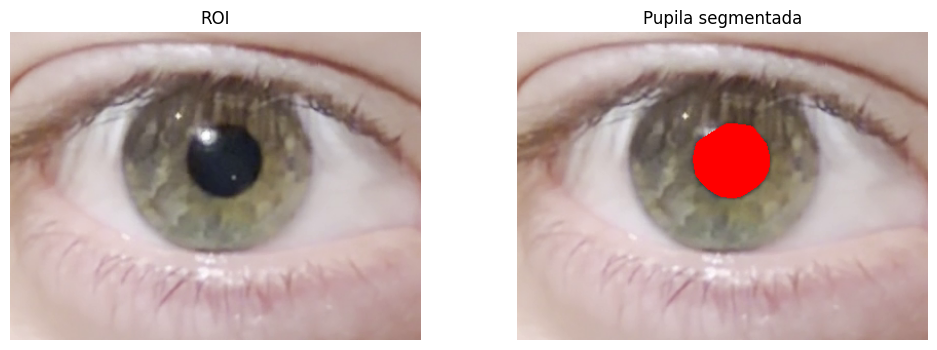

In [10]:
import sys
sys.path.append("..")     # para encontrar config.py y la carpeta src

import cv2
import numpy as np
import matplotlib.pyplot as plt
from config import VIDEO_PATH
from src.segmentacion import segmentar_pupila


# Mismo frame y ROI que en los módulos anteriores
FRAME_IDX = 778
x, y, w, h = 300, 950, 400, 300

cap = cv2.VideoCapture(str(VIDEO_PATH))
cap.set(cv2.CAP_PROP_POS_FRAMES, FRAME_IDX)
ok, frame = cap.read()
cap.release()

frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
roi = frame_rgb[y:y+h, x:x+w]
roi_gris = cv2.cvtColor(roi, cv2.COLOR_RGB2GRAY)

# Máscara de la pupila con el método del Módulo 2
mascara = segmentar_pupila(roi)

superpuesta = roi.copy()
superpuesta[mascara == 255] = [255, 0, 0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(roi)
axes[0].set_title("ROI")
axes[1].imshow(superpuesta)
axes[1].set_title("Pupila segmentada")
for ax in axes:
    ax.axis("off")
plt.show()

## 1. Descriptores Morfométricos y de Textura en el Frame Segmentado

### Descriptores morfométricos

A partir de la máscara binaria de la pupila se calculan:
- Área (A): cantidad de píxeles de la región.
- Perímetro (P): longitud del contorno de la región.
- Centroide $(X_c, Y_c)$: promedio de las coordenadas de los píxeles de la región.
- Circularidad: $C = \dfrac{4\pi A}{P^2}$. Vale 1 para un círculo perfecto y disminuye cuanto más irregular o alargada es la forma.
- Excentricidad: se ajusta a la región una elipse con los mismos momentos de segundo orden y se calcula la relación entre la distancia focal y su eje mayor. Vale 0 para un círculo y tiende a 1 para una forma alargada.
- Diámetro equivalente: diámetro de un círculo con la misma área que la región, $D = \sqrt{4A/\pi}$.

Área:                  4224 px
Perímetro:             241.0 px
Centroide (Xc, Yc):    (208.4, 124.7) px
Circularidad:          0.914
Excentricidad:         0.321
Diámetro equivalente:  73.3 px
Ejes de la elipse:     75.4 × 71.4 px


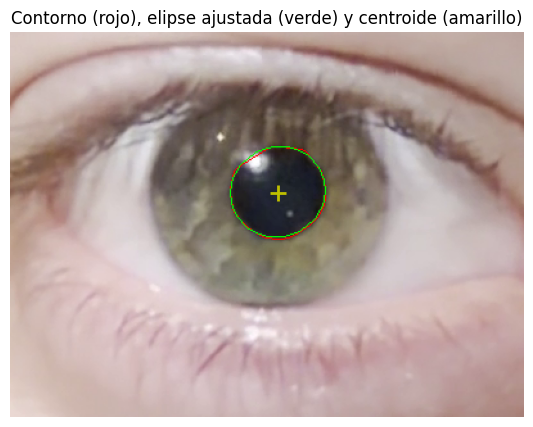

In [ ]:
from skimage.measure import regionprops, label

# Propiedades de la región blanca de la máscara
# label numera las regiones conectadas; regionprops calcula las medidas de cada una. Como hay una sola (la pupila), tomamos [0]
props = regionprops(label(mascara > 0))[0]

area = props.area
perimetro = props.perimeter
yc, xc = props.centroid                 
circularidad = 4 * np.pi * area / perimetro ** 2
excentricidad = props.eccentricity
diametro_eq = props.equivalent_diameter_area

print(f"Área:                  {area:.0f} px")
print(f"Perímetro:             {perimetro:.1f} px")
print(f"Centroide (Xc, Yc):    ({xc:.1f}, {yc:.1f}) px")
print(f"Circularidad:          {circularidad:.3f}")
print(f"Excentricidad:         {excentricidad:.3f}")
print(f"Diámetro equivalente:  {diametro_eq:.1f} px")
print(f"Ejes de la elipse:     {props.axis_major_length:.1f} × {props.axis_minor_length:.1f} px")


# Visualización: contorno, centroide y elipse ajustada
vis = roi.copy()
contornos, _ = cv2.findContours(mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
cv2.drawContours(vis, contornos, -1, (255, 0, 0), 1)

# Elipse con los mismos momentos que la región
# (OpenCV pide el ángulo en grados y los semiejes)
angulo = -np.degrees(props.orientation) + 90
cv2.ellipse(vis, (int(xc), int(yc)),
            (int(props.axis_major_length / 2), int(props.axis_minor_length / 2)),
            angulo, 0, 360, (0, 255, 0), 1)

plt.figure(figsize=(7, 5))
plt.imshow(vis)
plt.plot(xc, yc, "y+", markersize=12, mew=2)
plt.title("Contorno (rojo), elipse ajustada (verde) y centroide (amarillo)")
plt.axis("off")
plt.show()

La pupila segmentada en el frame 778 tiene un área de 4224 px y un perímetro de 241 px, con su centroide ubicado en (208,4; 124,7) px dentro de la ROI. Su diámetro equivalente, es decir, el de un círculo con la misma área, es de 73,3 px.

La circularidad obtenida es de 0,914, cercana a 1, lo que indica una forma muy próxima a un círculo. Parte de la diferencia respecto del valor ideal se debe a que el contorno está formado por píxeles discretos: el perímetro de una figura "escalonada" resulta algo mayor que el de un círculo continuo, lo que reduce la circularidad aunque la forma sea redonda. También contribuye el tramo recto que introduce la envolvente convexa en la zona del reflejo corneal.

La excentricidad es de 0,321, y la elipse ajustada tiene ejes de 75,4 y 71,4 px, por lo que el eje menor es aproximadamente un 95 % del mayor. Aunque el valor de excentricidad pueda parecer alto, esta medida es muy sensible cerca de la forma circular: una diferencia de solo el 5 % entre los ejes ya produce una excentricidad de alrededor de 0,3. La leve elongación puede deberse a que la cámara no estaba perfectamente frontal al ojo, lo que hace que la pupila se proyecte como una elipse, o a pequeñas irregularidades de la segmentación.

En conclusión, ambos descriptores indican que la pupila presenta una forma regular, sin deformaciones significativas.

### Textura de primer orden

La textura de primer orden describe la distribución de intensidades de una región a partir de su histograma, sin considerar la posición de los píxeles. Se calculan cuatro estadísticos:
- **Media:** intensidad promedio de la región.
- **Desvío estándar:** dispersión de las intensidades alrededor de la media; cuanto mayor, más contraste interno.
- **Entropía:** $H = -\sum_i p_i \log_2 p_i$, donde $p_i$ es la probabilidad de cada nivel de gris. Mide la aleatoriedad o complejidad de la distribución: es baja si predominan pocos niveles y alta si las intensidades están repartidas en muchos niveles.
- **Asimetría (skewness):** indica si el histograma tiene una cola hacia valores altos (positiva) o bajos (negativa).

Se calculan por separado en los canales R, G y B, sobre dos regiones: la **pupila**, obtenida con la segmentación del Módulo 2, y el **iris**, definido como el anillo entre el borde de la pupila y el borde externo del iris. El borde del iris se detecta con la transformada de Hough para círculos. Para la entropía, cada canal se cuantiza a 64 niveles de gris.

Iris: centro (202, 124) px, radio 94 px


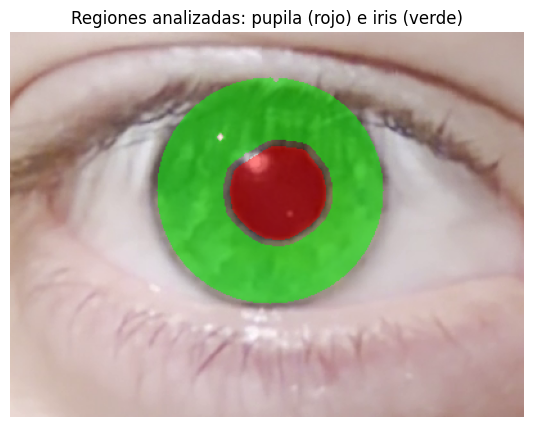

In [ ]:
# 1) Borde externo del iris con la transformada de Hough
# Radio aproximado de la pupila (a partir de su área)
radio_pupila = np.sqrt(area / np.pi)

# Suavizamos con mediana para que la textura del iris no genere
# círculos falsos
gris_suave = cv2.medianBlur(roi_gris, 7)

# HoughCircles busca círculos en la imagen:
circulos = cv2.HoughCircles(
    gris_suave, cv2.HOUGH_GRADIENT, dp=1, minDist=1000,
    param1=60, param2=20,
    minRadius=int(2 * radio_pupila), maxRadius=int(4 * radio_pupila)
)
x_iris, y_iris, radio_iris = circulos[0][0]
print(f"Iris: centro ({x_iris:.0f}, {y_iris:.0f}) px, radio {radio_iris:.0f} px")


# 2) Máscara del iris: anillo entre la pupila y el borde del iris
# Círculo del iris un 5 % más chico, para no incluir la esclerótica
disco_iris = np.zeros_like(roi_gris)
cv2.circle(disco_iris, (int(x_iris), int(y_iris)), int(0.95 * radio_iris), 255, -1)

# Pupila agrandada unos píxeles, para no incluir su borde
ee = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11))
pupila_agrandada = cv2.dilate(mascara, ee)

# Iris = disco del iris, sin la pupila y sin reflejos (píxeles muy claros)
mascara_iris = (disco_iris > 0) & (pupila_agrandada == 0) & (roi_gris < 170)
mascara_pupila = mascara > 0


# 3) Visualización
vis = roi.copy()
vis[mascara_iris] = (0.5 * vis[mascara_iris] + [0, 127, 0]).astype(np.uint8)
vis[mascara_pupila] = (0.5 * vis[mascara_pupila] + [127, 0, 0]).astype(np.uint8)

plt.figure(figsize=(7, 5))
plt.imshow(vis)
plt.title("Regiones analizadas: pupila (rojo) e iris (verde)")
plt.axis("off")
plt.show()

Media  Desvío  Entropía (bits)  Asimetría
Región Canal                                            
Pupila R       46.12   36.05             3.66       3.75
       G       46.30   35.51             3.55       3.94
       B       52.30   35.20             3.78       3.85
Iris   R      120.35   24.10             4.53       0.05
       G      109.62   27.19             4.67      -0.04
       B       95.65   24.52             4.58       0.13

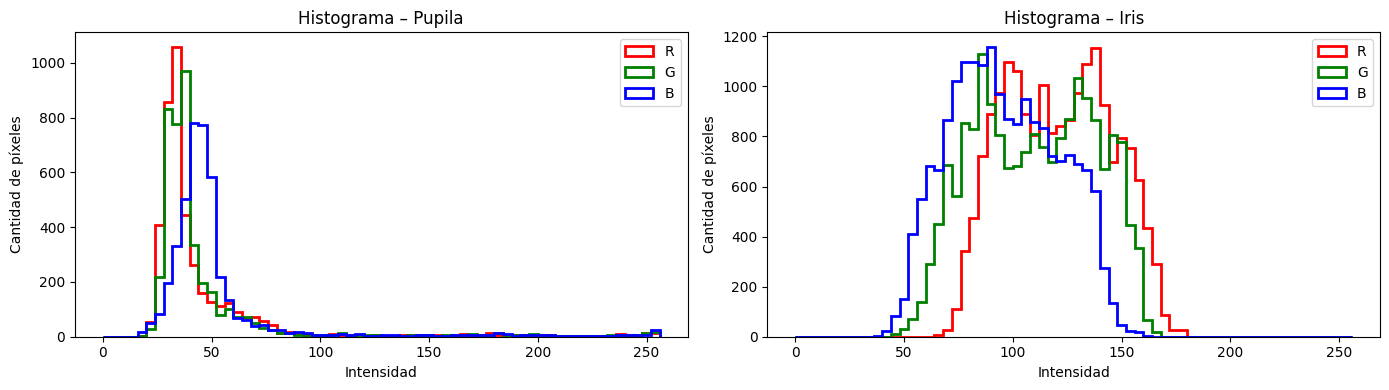

In [ ]:
import pandas as pd
from scipy.stats import skew


# Entropía de un conjunto de valores, cuantizados a 64 niveles
def entropia(valores, niveles=64):
    cuantizados = valores // (256 // niveles)               
    conteo = np.bincount(cuantizados, minlength=niveles)
    p = conteo / conteo.sum() # probabilidades
    p = p[p > 0] # log(0) no está definido
    return -np.sum(p * np.log2(p))

# Estadísticos por región y por canal
regiones = {"Pupila": mascara_pupila, "Iris": mascara_iris}
canales = {"R": 0, "G": 1, "B": 2}

filas = []
for nombre_region, region in regiones.items():
    for nombre_canal, c in canales.items():
        # Valores del canal solo dentro de la región (lista 1D de píxeles)
        valores = roi[:, :, c][region]
        filas.append({
            "Región": nombre_region,
            "Canal": nombre_canal,
            "Media": valores.mean(),
            "Desvío": valores.std(),
            "Entropía (bits)": entropia(valores),
            "Asimetría": skew(valores.astype(float)),
        })

df_primer_orden = pd.DataFrame(filas).set_index(["Región", "Canal"]).round(2)
display(df_primer_orden)


# Histogramas del iris en cada canal
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (nombre_region, region) in zip(axes, regiones.items()):
    for nombre_canal, c in canales.items():
        ax.hist(roi[:, :, c][region], bins=64, range=(0, 256),
                histtype="step", linewidth=2,
                color={"R": "red", "G": "green", "B": "blue"}[nombre_canal],
                label=nombre_canal)
    ax.set_title(f"Histograma – {nombre_region}")
    ax.set_xlabel("Intensidad")
    ax.set_ylabel("Cantidad de píxeles")
    ax.legend()
plt.tight_layout()
plt.show()

Para el análisis de textura se excluyeron de ambas regiones los píxeles correspondientes a reflejos corneales (intensidad en escala de grises mayor o igual a 170), ya que no representan tejido sino luz reflejada. Al excluirlos, el desvío estándar de la pupila se redujo de aproximadamente 36 a 19 niveles de gris.

Pupila: Presenta intensidades medias bajas en los tres canales (41 en R, 41 en G y 47 en B), con un histograma concentrado en un pico angosto entre 25 y 55. La entropía es la más baja de las dos regiones (entre 3,3 y 3,6 bits de un máximo de 6 bits para 64 niveles), lo que indica una región oscura y relativamente uniforme. Sin embargo, la asimetría sigue siendo alta y positiva (entre 3,1 y 3,6) lo cual se ve en el histograma que conserva una cola hacia intensidades mayores. Esta cola corresponde a los píxeles del borde de la pupila, que mezclan intensidades de la pupila y del iris, y al halo de los reflejos corneales, cuyos valores intermedios no se eliminan con el umbral utilizado. El valor algo más alto del canal B es coherente con el tono levemente azulado de las zonas oscuras de la imagen.

Iris: Presenta intensidades medias mayores, con R > G > B (120, 110 y 96), lo que corresponde al tono verde-amarronado de un iris claro. Su desvío estándar (entre 24 y 27) y su entropía (entre 4,5 y 4,7 bits) son mayores que los de la pupila, lo que refleja la mayor variabilidad de intensidades del estroma iridiano. La asimetría es prácticamente nula (entre −0,04 y 0,13), es decir, el histograma es aproximadamente simétrico. En los tres canales se observan dos picos, uno en intensidades bajas y otro en intensidades altas, lo que sugiere la presencia de dos tipos de zonas en el iris: regiones más oscuras y más claras del estroma, posiblemente acentuadas por la sombra del párpado sobre la parte superior.

Entre los canales del iris, el G presenta el mayor desvío (27,2) y la mayor entropía (4,67 bits), por lo que es el que muestra mayor variabilidad de intensidades. Igualmente, las diferencias entre canales son pequeñas, por lo que la comparación se retoma con los descriptores de segundo orden, que también consideran la disposición espacial de los píxeles.

### Textura de segundo orden (GLCM)

La Matriz de Co-ocurrencia de Niveles de Gris (GLCM) registra con qué frecuencia aparecen pares de píxeles con determinados niveles de gris, separados por una distancia y una dirección dadas. A diferencia de los estadísticos de primer orden, considera la disposición espacial de las intensidades. De ella se extraen cuatro atributos:
- Contraste: diferencia de intensidad entre píxeles vecinos. Es alto cuando hay cambios bruscos entre vecinos.
- Homogeneidad: cercanía de los valores a la diagonal de la matriz. Es alta cuando los vecinos tienen intensidades parecidas.
- Energía: uniformidad de la matriz. Es alta cuando se repiten pocos pares de niveles, es decir, en texturas ordenadas o uniformes.
- Correlación: dependencia lineal entre el nivel de un píxel y el de su vecino.

Cada canal (R, G, B) se cuantiza a 64 niveles y la GLCM se calcula con distancia de 1 píxel en cuatro direcciones (0°, 45°, 90° y 135°), promediando los atributos. Como el iris tiene forma de anillo, se analizan cuatro ventanas de 32 × 32 px ubicadas dentro del iris (arriba, abajo, izquierda y derecha de la pupila) y se promedian sus resultados.

Contraste        Homogeneidad        Energía        Correlación       
           mean    std         mean    std    mean    std        mean    std
Canal                                                                       
R         1.339  0.572        0.666  0.058   0.174  0.025       0.942  0.025
G         1.338  0.544        0.669  0.055   0.171  0.022       0.950  0.020
B         1.342  0.547        0.660  0.050   0.165  0.014       0.951  0.024

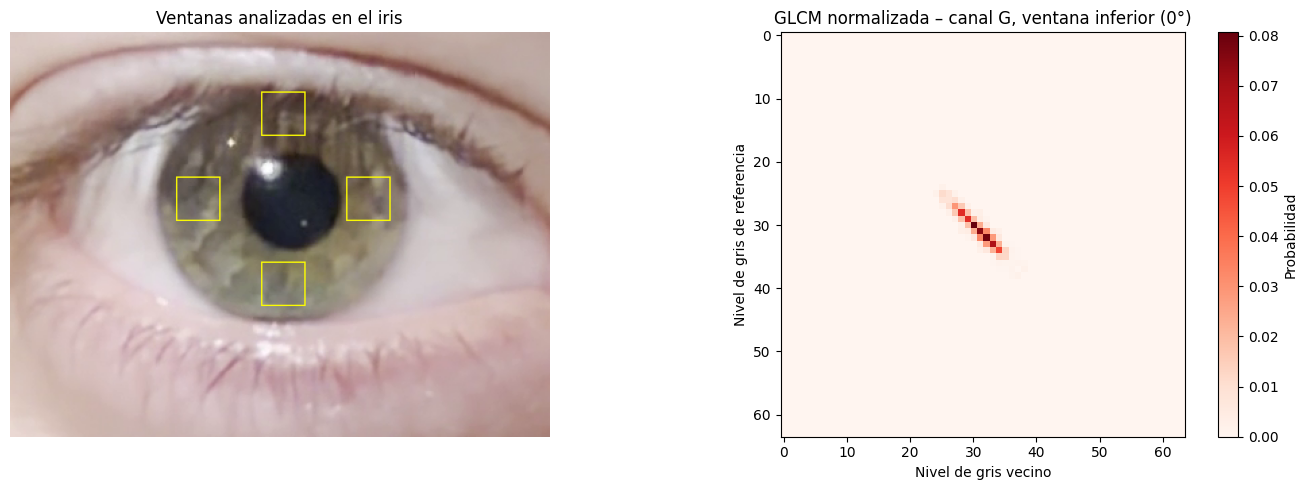

,Contraste,Homogeneidad,Energía,Correlación
Ventana,,,,
Arriba,2.104,0.594,0.148,0.933
Abajo,0.824,0.727,0.200,0.935
Izquierda,1.156,0.677,0.164,0.976
Derecha,1.267,0.679,0.171,0.954


In [15]:
from skimage.feature import graycomatrix, graycoprops


# Reducción de niveles de gris
NIVELES = 64

def reducir_niveles(imagen, n_grey):
    return np.floor_divide(imagen, 256 // n_grey)


# Ubicación de las 4 ventanas dentro del iris
TAM = 32 # tamaño de cada ventana (px)

# Las centramos a mitad de camino entre el borde de la pupila y el borde del iris, para que queden enteras dentro del anillo
r_medio = (radio_pupila + 0.95 * radio_iris) / 2

centros = {
    "Arriba":    (x_iris, y_iris - r_medio),
    "Abajo":     (x_iris, y_iris + r_medio),
    "Izquierda": (x_iris - r_medio, y_iris),
    "Derecha":   (x_iris + r_medio, y_iris),
}

# Esquina superior izquierda de cada ventana
ventanas = {nombre: (int(cx - TAM / 2), int(cy - TAM / 2))
            for nombre, (cx, cy) in centros.items()}

# GLCM y atributos por canal y por ventana
distancias = [1]
angulos = [0, np.pi/4, np.pi/2, 3*np.pi/4]       # 0°, 45°, 90°, 135°
atributos = ["contrast", "homogeneity", "energy", "correlation"]
nombres_atrib = ["Contraste", "Homogeneidad", "Energía", "Correlación"]

filas = []
for nombre_canal, c in canales.items():
    canal_red = reducir_niveles(roi[:, :, c], NIVELES)

    for nombre_ventana, (x0, y0) in ventanas.items():
        ventana = canal_red[y0:y0+TAM, x0:x0+TAM]

        glcm = graycomatrix(ventana, distances=distancias, angles=angulos,
                            levels=NIVELES, symmetric=True, normed=True)

        fila = {"Canal": nombre_canal, "Ventana": nombre_ventana}
        for atrib, nombre in zip(atributos, nombres_atrib):
            # graycoprops devuelve un valor por ángulo; los promediamos
            fila[nombre] = graycoprops(glcm, atrib).mean()
        filas.append(fila)

df_glcm = pd.DataFrame(filas)

# Resultado por canal: promedio y desvío de las 4 ventanas
resumen_glcm = df_glcm.groupby("Canal")[nombres_atrib].agg(["mean", "std"]).round(3)
display(resumen_glcm.loc[["R", "G", "B"]])


# Visualización: ventanas sobre la ROI y GLCM del canal G (ventana inferior)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

vis = roi.copy()
for nombre_ventana, (x0, y0) in ventanas.items():
    cv2.rectangle(vis, (x0, y0), (x0 + TAM, y0 + TAM), (255, 255, 0), 1)
axes[0].imshow(vis)
axes[0].set_title("Ventanas analizadas en el iris")
axes[0].axis("off")

x0, y0 = ventanas["Abajo"]
ventana_g = reducir_niveles(roi[:, :, 1], NIVELES)[y0:y0+TAM, x0:x0+TAM]
glcm_g = graycomatrix(ventana_g, [1], [0], levels=NIVELES, symmetric=True, normed=True)
im = axes[1].imshow(glcm_g[:, :, 0, 0], cmap="Reds")
plt.colorbar(im, ax=axes[1], label="Probabilidad")
axes[1].set_title("GLCM normalizada – canal G, ventana inferior (0°)")
axes[1].set_xlabel("Nivel de gris vecino")
axes[1].set_ylabel("Nivel de gris de referencia")

plt.tight_layout()
plt.show()

display(df_glcm[df_glcm["Canal"] == "G"].set_index("Ventana")[nombres_atrib].round(3))

Los atributos de la GLCM resultan prácticamente iguales en los tres canales: el contraste es de 1,34 en R, G y B, la homogeneidad está entre 0,660 y 0,669, la energía entre 0,165 y 0,174, y la correlación entre 0,942 y 0,951. Las diferencias entre canales son mucho menores que la variación entre las cuatro ventanas de un mismo canal: por ejemplo, el desvío del contraste entre ventanas es de aproximadamente 0,55, mientras que la diferencia entre canales es menor a 0,01. Es decir, la textura cambia más según la zona del iris que se analiza que según el canal de color.

La GLCM del canal G en la ventana inferior muestra los valores concentrados en una franja angosta alrededor de la diagonal. Esto indica que los píxeles vecinos tienen casi siempre niveles de gris muy parecidos, lo que es coherente con la alta homogeneidad y la alta correlación (cercana a 0,95) obtenidas. A la distancia de 1 píxel, la textura del iris resulta suave: los cambios de intensidad son graduales. Además, los valores ocupan solo un rango reducido de los 64 niveles (aproximadamente entre 25 y 37 en esa ventana), lo que muestra que el contraste dentro de cada zona del iris es bajo.

Respecto de qué canal aporta mayor riqueza textural del estroma iridiano, ningún canal se destaca de forma significativa. En la textura de primer orden, el canal G presentó el mayor desvío y la mayor entropía, y en la de segundo orden el canal B presenta una energía y una homogeneidad levemente menores; pero en ambos casos las diferencias son pequeñas y están dentro de la variabilidad entre ventanas.

Al comparar las ventanas en el canal G, la ventana superior presenta el mayor contraste (2,10) y la menor homogeneidad (0,594) y energía (0,148), mientras que la inferior presenta el menor contraste (0,82) y la mayor homogeneidad (0,727) y energía (0,200). Las ventanas laterales tienen valores intermedios. La mayor heterogeneidad de la zona superior puede atribuirse a la sombra del párpado y de las pestañas sobre el iris, que agregan cambios de intensidad que no pertenecen al estroma. Esto muestra que la textura medida depende de la región analizada y que, para caracterizar el iris, conviene considerar varias zonas o excluir las afectadas por el párpado.